<a href="https://colab.research.google.com/github/Shaurya-XD/MotionMirror/blob/main/MotionMirrorP1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
import os
#os helps with paths and basic filesystem operations

PROJECT_DIR = "/content/drive/MyDrive/MotionMirror"

# stores the original HMDB51 archives
HMDB_DRIVE_DIR = os.path.join(PROJECT_DIR, "datasets", "HMDB51")

#temporary storage of the download
HMDB_LOCAL_DIR = "/content/hmdb51_download"

os.makedirs(HMDB_DRIVE_DIR, exist_ok=True)
os.makedirs(HMDB_LOCAL_DIR, exist_ok=True)

print(f"Project Directory: {PROJECT_DIR}")
print("Drive dataset folder:", HMDB_DRIVE_DIR)
print("Temporary Colab folder:", HMDB_LOCAL_DIR)

Project Directory: /content/drive/MyDrive/MotionMirror
Drive dataset folder: /content/drive/MyDrive/MotionMirror/datasets/HMDB51
Temporary Colab folder: /content/hmdb51_download


In [3]:
from huggingface_hub import hf_hub_download

# Download the full original HMDB51 video archive.
VIDEO_ARCHIVE = hf_hub_download(
    repo_id="Serrelab/hmdb51",
    filename="hmdb51_org.rar",
    repo_type="dataset",
    local_dir=HMDB_LOCAL_DIR
)

# Download the official train/test split archive.
SPLIT_ARCHIVE = hf_hub_download(
    repo_id="Serrelab/hmdb51",
    filename="test_train_splits.rar",
    repo_type="dataset",
    local_dir=HMDB_LOCAL_DIR
)

print("Video archive:", VIDEO_ARCHIVE)
print("Split archive:", SPLIT_ARCHIVE)

hmdb51_org.rar: reconstructing file:   0%|          |  0.00B / 2.12GB            

hmdb51_org.rar: downloading bytes:           |  0.00B            

test_train_splits.rar: reconstructing file:   0%|          |  0.00B /  200kB            

test_train_splits.rar: downloading bytes:           |  0.00B            

Video archive: /content/hmdb51_download/hmdb51_org.rar
Split archive: /content/hmdb51_download/test_train_splits.rar


In [4]:
def show_file_size(path):
  if os.path.exists(path):
    size_mb = os.path.getsize(path) / (1024**2)
    print(f"{os.path.basename(path)} : {size_mb} Mb")
  else:
    print(f"{os.path.basename(path)} not found")

show_file_size(VIDEO_ARCHIVE)
show_file_size(SPLIT_ARCHIVE)

hmdb51_org.rar : 2025.6119976043701 Mb
test_train_splits.rar : 0.1902780532836914 Mb


In [5]:
# shutil helps you copy, move, delete, and archive files/folders.
import shutil

DRIVE_VIDEO_ARCHIVE = os.path.join(
    HMDB_DRIVE_DIR,
    "hmdb51_org.rar"
)

DRIVE_SPLIT_ARCHIVE = os.path.join(
    HMDB_DRIVE_DIR,
    "test_train_splits.rar"
)

# Copy the full video dataset to drive.
shutil.copy2(
    VIDEO_ARCHIVE,
    DRIVE_VIDEO_ARCHIVE
)

# Copy the official train/test splits to drive.
shutil.copy2(
    SPLIT_ARCHIVE,
    DRIVE_SPLIT_ARCHIVE
)

print("HMDB51 successfully backed up to Google Drive.")

HMDB51 successfully backed up to Google Drive.


In [6]:
# HMDB51 is distributed as .rar archives.
# Install the unrar utility so Colab can extract them.

!apt-get update -qq
!apt-get install -y -qq unrar

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


In [7]:
SELECTED_CLASSES = [
    "clap",
    "jump",
    "pushup",
    "run",
    "walk",
    "wave"
]

print(f"Selected Classes: {SELECTED_CLASSES}")

Selected Classes: ['clap', 'jump', 'pushup', 'run', 'walk', 'wave']


In [8]:
WORK_DIR = "/content/HMDB51_P1"

CLASS_ARCHIVE_DIR = os.path.join(
    WORK_DIR,
    "class_archives"
)

VIDEO_DIR = os.path.join(
    WORK_DIR,
    "videos"
)

SPLIT_DIR = os.path.join(
    WORK_DIR,
    "splits"
)

os.makedirs(CLASS_ARCHIVE_DIR, exist_ok=True)
os.makedirs(VIDEO_DIR, exist_ok=True)
os.makedirs(SPLIT_DIR, exist_ok=True)

print("Working directory:", WORK_DIR)

Working directory: /content/HMDB51_P1


In [9]:
# Extract the outer HMDB51 archive.
# This produces one .rar archive for each of the 51 action classes.
# x means extract only the specified archive while preserving the internal floder structure
# -o+ overwrite existing files automatically

!unrar x -o+ "$VIDEO_ARCHIVE" "$CLASS_ARCHIVE_DIR/"


UNRAR 7.00 freeware      Copyright (c) 1993-2024 Alexander Roshal


Extracting from /content/hmdb51_download/hmdb51_org.rar

Extracting  /content/HMDB51_P1/class_archives/shoot_gun.rar                0%  1%  OK 
Extracting  /content/HMDB51_P1/class_archives/sit.rar                      1%  2%  3%  OK 
Extracting  /content/HMDB51_P1/class_archives/situp.rar                    3%  4%  OK 
Extracting  /content/HMDB51_P1/class_archives/smile.rar                    4%  5%  OK 
Extracting  /content/HMDB51_P1/class_archives/smoke.rar                    5%  6%  7%  OK 
Extracting  /content/HMDB51_P1/class_archives/somersault.rar               7%  8%  9%  OK 
Extracting  /content/HMDB51_P1/class_archives/stand.rar                    9% 10% 11%  OK 
Extracting  /content/HMDB51_P1/class_archives/swing_baseball.rar          11% 12% 13%  OK 
Extracting  /content/HMDB51_P1/cla

In [10]:
# Verify that all six action archives are present before extracting them.

missing_classes = []

for action in SELECTED_CLASSES:
    ARCHIVE_PATH = os.path.join(
        CLASS_ARCHIVE_DIR,
        f"{action}.rar"
    )

    if os.path.exists(ARCHIVE_PATH):
        print(f"{action}: FOUND")
    else:
        print(f"{action}: MISSING")
        missing_classes.append(action)

if len(missing_classes) == 0:
    print("\nAll selected classes are available.")
else:
    print("\nMissing classes:", missing_classes)

clap: FOUND
jump: FOUND
pushup: FOUND
run: FOUND
walk: FOUND
wave: FOUND

All selected classes are available.


In [11]:
# Extract the actual videos

for action in SELECTED_CLASSES:

    ARCHIVE_PATH = os.path.join(
        CLASS_ARCHIVE_DIR,
        f"{action}.rar"
    )

    print(f"\nExtracting {action}...")

    # Each class will get its own folder.
    ACTION_OUTPUT_DIR = os.path.join(
        VIDEO_DIR,
        action
    )

    os.makedirs(ACTION_OUTPUT_DIR, exist_ok=True)

    # Extract the class-specific archive.
    !unrar x -o+ "$ARCHIVE_PATH" "$ACTION_OUTPUT_DIR"

print("Selected classes extracted successfully.")


Extracting clap...

UNRAR 7.00 freeware      Copyright (c) 1993-2024 Alexander Roshal


Extracting from /content/HMDB51_P1/class_archives/clap.rar

Creating    /content/HMDB51_P1/videos/clap/clap                       OK
Extracting  /content/HMDB51_P1/videos/clap/clap/#20_Rhythm_clap_u_nm_np1_fr_goo_0.avi       0%  OK 
Extracting  /content/HMDB51_P1/videos/clap/clap/#20_Rhythm_clap_u_nm_np1_fr_goo_1.avi       0%  1%  OK 
Extracting  /content/HMDB51_P1/videos/clap/clap/#20_Rhythm_clap_u_nm_np1_fr_goo_2.avi       1%  OK 
Extracting  /content/HMDB51_P1/videos/clap/clap/#20_Rhythm_clap_u_nm_np1_le_goo_3.avi       1%  2%  OK 
Extracting  /content/HMDB51_P1/videos/clap/clap/#20_Rhythm_clap_u_nm_np1_le_goo_4.avi       2%  3%  OK 
Extracting  /content/HMDB51_P1/videos/clap/clap/#20_Rhythm_clap_u_nm_np1_le_goo_5.avi       3%  OK 
Extracting  /content/HMDB51_P1/videos/clap/clap/103_years_old_japanese_woman__Nao_is_clapping_with_p

In [12]:
# Extract HMDB51's official train/test split definitions.
# We will later use Split 1 for Prototype 1.

!unrar x -o+ "$SPLIT_ARCHIVE" "$SPLIT_DIR/"


UNRAR 7.00 freeware      Copyright (c) 1993-2024 Alexander Roshal


Extracting from /content/hmdb51_download/test_train_splits.rar

Creating    /content/HMDB51_P1/splits/testTrainMulti_7030_splits      OK
Extracting  /content/HMDB51_P1/splits/testTrainMulti_7030_splits/brush_hair_test_split1.txt       0%  OK 
Extracting  /content/HMDB51_P1/splits/testTrainMulti_7030_splits/brush_hair_test_split2.txt       1%  OK 
Extracting  /content/HMDB51_P1/splits/testTrainMulti_7030_splits/brush_hair_test_split3.txt       1%  OK 
Extracting  /content/HMDB51_P1/splits/testTrainMulti_7030_splits/cartwheel_test_split1.txt       2%  OK 
Extracting  /content/HMDB51_P1/splits/testTrainMulti_7030_splits/cartwheel_test_split2.txt       2%  OK 
Extracting  /content/HMDB51_P1/splits/testTrainMulti_7030_splits/cartwheel_test_split3.txt       3%  OK 
Extracting  /content/HMDB51_P1/splits/testTrainMulti_7030_splits/catch_test_split1.txt       4%  O

In [13]:
# Count how many .avi video files exist for each selected action.

video_counts = {}

for action in SELECTED_CLASSES:

    ACTION_DIR = os.path.join(
        VIDEO_DIR,
        action,
        action
    )

    videos = [
        file_name
        for file_name in os.listdir(ACTION_DIR)
        if file_name.lower().endswith(".avi")
    ]

    video_counts[action] = len(videos)

    print(f"{action}: {len(videos)} videos")

print("Total videos:", sum(video_counts.values()))

clap: 130 videos
jump: 151 videos
pushup: 103 videos
run: 232 videos
walk: 548 videos
wave: 104 videos
Total videos: 1268


In [14]:
# Confirm that Split 1 exists for every selected action.

for action in SELECTED_CLASSES:

    split_file = os.path.join(
        SPLIT_DIR,
        "testTrainMulti_7030_splits",
        f"{action}_test_split1.txt"
    )

    if os.path.exists(split_file):
        print(f"{action}: Split 1 found")
    else:
        print(f"{action}: Split 1 MISSING")

clap: Split 1 found
jump: Split 1 found
pushup: Split 1 found
run: Split 1 found
walk: Split 1 found
wave: Split 1 found


In [15]:
# Display the first 10 entries from the official walk Split 1 file.

EXAMPLE_SPLIT = os.path.join(
    SPLIT_DIR,
    "testTrainMulti_7030_splits",
    "walk_test_split3.txt"
)

with open(EXAMPLE_SPLIT, "r") as file:
    for _ in range(10):
        print(file.readline().strip())

20060723sfjffbitemebaby_walk_u_nm_np1_fr_med_0.avi 0
20060723sfjffbumblebeesuitman_walk_u_cm_np2_fr_med_0.avi 0
20060723sfjffcomeback_walk_u_cm_np1_ri_med_2.avi 0
20060723sfjffcookies_walk_u_nm_np1_ba_med_1.avi 1
20060723sfjffcookies_walk_u_nm_np1_fr_med_0.avi 0
20060723sfjffjewcy_walk_f_cm_np1_ba_med_2.avi 0
20060723sfjffjewcy_walk_f_nm_np1_fr_med_0.avi 0
20060723sfjffjewcy_walk_f_nm_np1_fr_med_1.avi 0
20060723sfjffjewgotmail_walk_f_cm_np2_ba_med_2.avi 2
20060723sfjffjewgotmail_walk_f_nm_np1_fr_med_1.avi 0


In [16]:
# HMDB provides three official train/test folds.
# We will use Fold 1 throughout Prototype 1.

OFFICIAL_FOLD = 1

# 20% of HMDB's official training videos will be used for validation.
VALIDATION_FRACTION = 0.20

SPLIT_SUBDIR = "testTrainMulti_7030_splits"

CLASS_TO_INDEX = {
    action: index
    for index, action in enumerate(SELECTED_CLASSES)
}

INDEX_TO_CLASS = {
    index: action
    for action, index in CLASS_TO_INDEX.items()
}

print("Class mapping:", CLASS_TO_INDEX)
print("Class mapping:", INDEX_TO_CLASS)

Class mapping: {'clap': 0, 'jump': 1, 'pushup': 2, 'run': 3, 'walk': 4, 'wave': 5}
Class mapping: {0: 'clap', 1: 'jump', 2: 'pushup', 3: 'run', 4: 'walk', 5: 'wave'}


In [17]:
import pandas as pd

# Each row in this list will represent one video.
records = []

# Keep track of missing files
missing_videos = []

for action in SELECTED_CLASSES:
    ACTION_DIR = os.path.join(
        VIDEO_DIR,
        action,
        action
    )

    SPLIT_FILE = os.path.join(
        SPLIT_DIR,
        SPLIT_SUBDIR,
        f"{action}_test_split{OFFICIAL_FOLD}.txt"
    )

    with open(SPLIT_FILE, "r") as file:

        for line in file:

            line = line.strip()

            # Ignore empty lines if any are present.
            if not line:
                continue

            parts = line.split()

            if len(parts) != 2:
                raise ValueError(
                    f"Unexpected line in {SPLIT_FILE}: {line}"
                )

            video_name = parts[0]
            split_flag = int(parts[1])

            # HMDB split labels:
            # 1 = training
            # 2 = testing
            # 0 = not used in this fold
            if split_flag == 0:
                continue

            if split_flag not in (1, 2):
                raise ValueError(
                    f"Unexpected split flag {split_flag} "
                    f"for video {video_name}"
                )

            VIDEO_PATH = os.path.join(
                ACTION_DIR,
                video_name
            )

            if not os.path.exists(VIDEO_PATH):
                missing_videos.append(VIDEO_PATH)
                continue

            official_split = (
                "train"
                if split_flag == 1
                else "test"
            )

            records.append({
                "video_path": VIDEO_PATH,
                "video_name": video_name,
                "action": action,
                "label": CLASS_TO_INDEX[action],
                "official_split": official_split
            })


# Stop immediately if the split files reference videos
# that are not present in our extracted folders.
if missing_videos:
    raise FileNotFoundError(
        f"{len(missing_videos)} videos could not be found."
    )


official_manifest = pd.DataFrame(records)

print("Total usable videos:", len(official_manifest))

official_manifest.head()

Total usable videos: 600


,video_path,video_name,action,label,official_split
0,/content/HMDB51_P1/videos/clap/clap/#20_Rhythm...,#20_Rhythm_clap_u_nm_np1_fr_goo_0.avi,clap,0,train
1,/content/HMDB51_P1/videos/clap/clap/#20_Rhythm...,#20_Rhythm_clap_u_nm_np1_fr_goo_1.avi,clap,0,train
2,/content/HMDB51_P1/videos/clap/clap/#20_Rhythm...,#20_Rhythm_clap_u_nm_np1_fr_goo_2.avi,clap,0,train
3,/content/HMDB51_P1/videos/clap/clap/#20_Rhythm...,#20_Rhythm_clap_u_nm_np1_le_goo_3.avi,clap,0,train
4,/content/HMDB51_P1/videos/clap/clap/#20_Rhythm...,#20_Rhythm_clap_u_nm_np1_le_goo_4.avi,clap,0,train


In [18]:
official_manifest.shape

(600, 5)

In [19]:
# Count how many official training and testing videos
# exist for every selected action.

official_counts = (
    official_manifest
    .groupby(["action", "official_split"])
    .size()
)

print(official_counts)

print("Total official training videos:",
      (official_manifest["official_split"] == "train").sum())

print("Total official testing videos:",
      (official_manifest["official_split"] == "test").sum())

action  official_split
clap    test              30
        train             70
jump    test              30
        train             70
pushup  test              30
        train             70
run     test              30
        train             70
walk    test              30
        train             70
wave    test              30
        train             70
dtype: int64
Total official training videos: 420
Total official testing videos: 180


In [20]:
from sklearn.model_selection import train_test_split

SEED = 7

official_train_df = official_manifest[
    official_manifest["official_split"] == "train"
].copy()

test_df = official_manifest[
    official_manifest["official_split"] == "test"
].copy()

# stratify ensures that every action keeps the same class balance.
train_df, val_df = train_test_split(
    official_train_df,
    test_size=VALIDATION_FRACTION,
    random_state=SEED,
    stratify=official_train_df["action"]
)


# Reset indices so each DataFrame has clean sequential rows.
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Training videos:  ", len(train_df))
print("Validation videos:", len(val_df))
print("Testing videos:   ", len(test_df))

Training videos:   336
Validation videos: 84
Testing videos:    180


In [21]:
# Checking for data leakage

train_paths = set(train_df["video_path"])
val_paths = set(val_df["video_path"])
test_paths = set(test_df["video_path"])

train_val_overlap = train_paths.intersection(val_paths)
train_test_overlap = train_paths.intersection(test_paths)
val_test_overlap = val_paths.intersection(test_paths)

print("Train v/s Validation overlap:",
      len(train_val_overlap))

print("Train v/s Test overlap:",
      len(train_test_overlap))

print("Validation v/s Test overlap:",
      len(val_test_overlap))

Train v/s Validation overlap: 0
Train v/s Test overlap: 0
Validation v/s Test overlap: 0


In [22]:
# Add our final split names before combining the datasets.

train_df["split"] = "train"
val_df["split"] = "validation"
test_df["split"] = "test"


# Combine everything into one final manifest.
manifest_df = pd.concat(
    [
        train_df,
        val_df,
        test_df
    ],
    ignore_index=True
)

# Keep only the columns that will be useful later.
manifest_df = manifest_df[
    [
        "video_path",
        "video_name",
        "action",
        "label",
        "split"
    ]
]

print("Final manifest size:", len(manifest_df))

manifest_df.head()

Final manifest size: 600


,video_path,video_name,action,label,split
0,/content/HMDB51_P1/videos/wave/wave/IndianaJon...,IndianaJonesandTheTempleofDoom_wave_h_nm_np1_f...,wave,5,train
1,/content/HMDB51_P1/videos/clap/clap/Boom_Snap_...,Boom_Snap_Clap_clap_u_nm_np1_fr_med_1.avi,clap,0,train
2,/content/HMDB51_P1/videos/pushup/pushup/Chest_...,Chest_Muscle_Group_(for_sexy_arms__shoulders__...,pushup,2,train
3,/content/HMDB51_P1/videos/jump/jump/THE_PROTEC...,THE_PROTECTOR_jump_f_cm_np1_fr_bad_29.avi,jump,1,train
4,/content/HMDB51_P1/videos/clap/clap/boom-snap-...,boom-snap-clap_clap_u_nm_np1_fr_med_3.avi,clap,0,train


In [23]:
# Saving mainfest in google drive.

MANIFEST_DIR = os.path.join(
    HMDB_DRIVE_DIR,
    "metadata"
)

os.makedirs(
    MANIFEST_DIR,
    exist_ok=True
)

MANIFEST_PATH = os.path.join(
    MANIFEST_DIR,
    "p1_split1_manifest.csv"
)

manifest_df.to_csv(
    MANIFEST_PATH,
    index=False
)

print("Manifest saved to:")
print(MANIFEST_PATH)

Manifest saved to:
/content/drive/MyDrive/MotionMirror/datasets/HMDB51/metadata/p1_split1_manifest.csv


In [24]:
import cv2 # OpenCV for video decoding
import random
import numpy as np
import torch

from torchvision.transforms import RandomResizedCrop
from torchvision.transforms import functional as TF # Contains transformation functions
from torchvision.transforms.functional import InterpolationMode # It determines how the new pixels are calculated when an image changes size or geometry.

NUM_FRAMES = 16

FRAME_SIZE = 112

TEMPORAL_CROP_RANGE = (0.75, 1.00) # randomly choose a continuous portion of the videos timeline

SPATIAL_CROP_SCALE = (0.80, 1.00)

SPATIAL_ASPECT_RATIO = (0.90, 1.10)

HORIZONTAL_FLIP_PROBABILITY = 0.50

MAX_ROTATION_DEGREES = 7.0
MAX_TRANSLATION_FRACTION = 0.05
SPATIAL_SCALE_RANGE = (0.95, 1.05) # zoom in or out

BRIGHTNESS_RANGE = (0.85, 1.15)
CONTRAST_RANGE = (0.85, 1.15)
SATURATION_RANGE = (0.90, 1.10)

BLUR_PROBABILITY = 0.10


# Normalization statistics used by the official
# Kinetics-400 pretrained R(2+1)D-18 weights.
# The Kinetics mean represents the average pixel intensity for each color channel, calculated from the preprocessing statistics associated with the Kinetics dataset.
KINETICS_MEAN = [0.43216, 0.394666, 0.37645]
# Kinetics standard deviation represents the per-channel spread of pixel intensities and is used to scale normalized video frames consistently with the pretrained model's input distribution.
KINETICS_STD = [0.22803, 0.22145, 0.216989]

print("Frames per clip:", NUM_FRAMES)
print("Frame size:", FRAME_SIZE)

Frames per clip: 16
Frame size: 112


In [25]:
def decode_video(video_path):
    video_capture = cv2.VideoCapture(video_path) # read/ open a video file

    if not video_capture.isOpened():
        raise RuntimeError(
            f"Could not open video: {video_path}"
        )

    fps = video_capture.get(cv2.CAP_PROP_FPS)

    frames = []

    while True:

        success, frame = video_capture.read()

        if not success:
            break

        # OpenCV reads images as BGR.
        # Our pretrained PyTorch model expects RGB.
        frame = cv2.cvtColor(
            frame,
            cv2.COLOR_BGR2RGB
        )

        frames.append(frame)

    video_capture.release() # close a video file

    if len(frames) == 0:
        raise RuntimeError(
            f"No frames were decoded from: {video_path}"
        )


    # [T, H, W, C] -> [T, C, H, W]
    frames = np.stack(frames) # creates a new first dimesion, which corresponds to frame no.

    frames = torch.from_numpy(frames) # convert into tensor

    frames = frames.permute(
        0,
        3,
        1,
        2
    )

    # Convert uint8 [0,255] into float [0,1].
    frames = frames.float() / 255.0

    return frames, fps

In [26]:
def sample_temporal_frames(frames, training):

    total_frames = frames.shape[0]

    if training:
        crop_ratio = random.uniform(
            *TEMPORAL_CROP_RANGE
        ) # * means unpack the tuple, and chooses a random decimal in the range

        temporal_window = max(
            1,
            round(total_frames * crop_ratio)
        ) # how many frames to consider in the temporal range

        temporal_window = min(
            temporal_window,
            total_frames
        )

        # Randomly choose where the temporal window begins.
        max_start = total_frames - temporal_window

        start_frame = (
            random.randint(0, max_start)
            if max_start > 0
            else 0
        )

        end_frame = (
            start_frame
            + temporal_window
            - 1
        )

    else:

        # Validation/testing uses the whole video
        start_frame = 0
        end_frame = total_frames - 1

    # produces evenly spaced numbers between a start and end value
    frame_indices = torch.linspace(
        start_frame,
        end_frame,
        steps=NUM_FRAMES
    )


    frame_indices = (
        frame_indices
        .round() # Cause linespace produces floats
        .long() # pytorch uses long
        .clamp(
            0,
            total_frames - 1
        ) # to make sure all the indices are in a valid range
    )

    sampled_frames = frames[
        frame_indices
    ]

    return sampled_frames, frame_indices

In [27]:
def apply_training_spatial_augmentation(frames):
  # Generate parameters using one frame then apply to all frames to prevent jitter

    top, left, height, width = (
        RandomResizedCrop.get_params(
            frames[0],
            scale=SPATIAL_CROP_SCALE,
            ratio=SPATIAL_ASPECT_RATIO
        )
    )

    frames = TF.resized_crop(
        frames,
        top=top,
        left=left,
        height=height,
        width=width,
        size=[FRAME_SIZE, FRAME_SIZE],
        interpolation=InterpolationMode.BILINEAR,
        antialias=True # to reduce jitter/ noise
    )

    if random.random() < HORIZONTAL_FLIP_PROBABILITY:
        frames = TF.hflip(frames)

    angle = random.uniform(
        -MAX_ROTATION_DEGREES,
        MAX_ROTATION_DEGREES
    )

    max_translation = round(
        FRAME_SIZE
        * MAX_TRANSLATION_FRACTION
    )

    translate_x = random.randint(
        -max_translation,
        max_translation
    )

    translate_y = random.randint(
        -max_translation,
        max_translation
    )

    spatial_scale = random.uniform(
        *SPATIAL_SCALE_RANGE
    )

    frames = TF.affine( # for geometric transformations
        frames,
        angle=angle,
        translate=[
            translate_x,
            translate_y
        ],
        scale=spatial_scale,
        shear=[0.0, 0.0], # slants an image
        interpolation=InterpolationMode.BILINEAR
    )

    brightness_factor = random.uniform(
        *BRIGHTNESS_RANGE
    )

    contrast_factor = random.uniform(
        *CONTRAST_RANGE
    )

    saturation_factor = random.uniform(
        *SATURATION_RANGE
    )

    frames = TF.adjust_brightness(
        frames,
        brightness_factor
    )

    frames = TF.adjust_contrast(
        frames,
        contrast_factor
    )

    frames = TF.adjust_saturation(
        frames,
        saturation_factor
    )

    if random.random() < BLUR_PROBABILITY:

        frames = TF.gaussian_blur(
            frames,
            kernel_size=[3, 3] # kernel that is used to calculate the blur
        )


    # Augmentation operations can occasionally
    # move values slightly outside [0,1].
    frames = frames.clamp(
        0.0,
        1.0
    )

    return frames

In [28]:
def apply_evaluation_spatial_preprocessing(frames):

    # Resize all frames to the pretrained model's
    # standard intermediate resolution.
    frames = TF.resize(
        frames,
        size=[128, 171],
        interpolation=InterpolationMode.BILINEAR,
        antialias=True
    )

    # Take a deterministic center crop.
    frames = TF.center_crop(
        frames,
        output_size=[
            FRAME_SIZE,
            FRAME_SIZE
        ]
    )

    return frames

In [29]:
def normalize_video_clip(frames):

    mean = torch.tensor(
        KINETICS_MEAN,
        dtype=frames.dtype,
        device=frames.device
    ).view(
        1,
        3,
        1,
        1
    )

    std = torch.tensor(
        KINETICS_STD,
        dtype=frames.dtype,
        device=frames.device
    ).view(
        1,
        3,
        1,
        1
    )

    frames = (
        frames - mean
    ) / std

    frames = frames.permute(
        1,
        0,
        2,
        3
    )

    return frames

In [30]:
def prepare_video_clip(
    video_path,
    training
):

    # Decode the complete video.
    frames, fps = decode_video(
        video_path
    )

    # Select exactly NUM_FRAMES frames.
    frames, frame_indices = sample_temporal_frames(
        frames,
        training=training
    )

    # Apply either random training augmentation or deterministic evaluation preprocessing.
    if training:
        frames = apply_training_spatial_augmentation(
            frames
        )

    else:
        frames = apply_evaluation_spatial_preprocessing(
            frames
        )


    # Save an unnormalized copy to visually inspect what the network sees.
    display_frames = frames.clone()

    # Apply Kinetics normalization and convert to [C, T, H, W].
    model_clip = normalize_video_clip(
        frames
    )

    return (
        model_clip,
        display_frames,
        frame_indices,
        fps
    )

In [31]:
# Select one training video from our manifest.
sample_row = train_df.iloc[100]

sample_video_path = sample_row["video_path"]
sample_action = sample_row["action"]

# Run the training preprocessing pipeline.
(
    sample_clip,
    sample_display_frames,
    sample_indices,
    sample_fps
) = prepare_video_clip(
    video_path=sample_video_path,
    training=True
)

print("Action:", sample_action)

print(
    "Original video FPS:",
    sample_fps
)

print(
    "Selected frame indices:",
    sample_indices.tolist()
)

print(
    "Model input shape:",
    sample_clip.shape
)

print(
    "Display frames shape:",
    sample_display_frames.shape
)

Action: walk
Original video FPS: 30.0
Selected frame indices: [16, 29, 42, 56, 69, 82, 95, 108, 122, 135, 148, 161, 174, 188, 201, 214]
Model input shape: torch.Size([3, 16, 112, 112])
Display frames shape: torch.Size([16, 3, 112, 112])


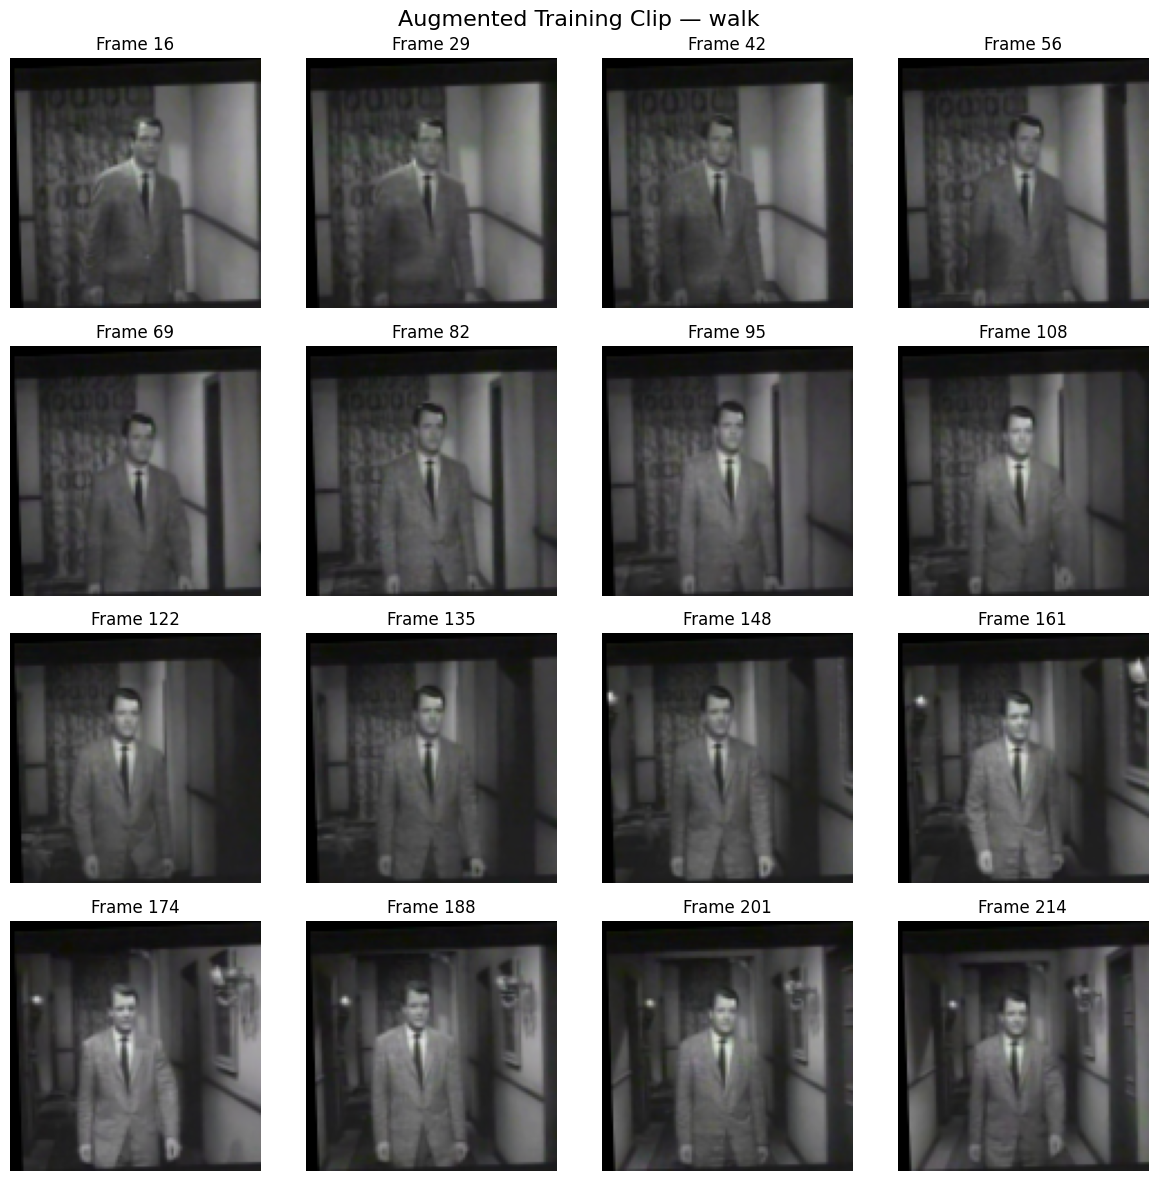

In [32]:
import matplotlib.pyplot as plt

figure, axes = plt.subplots(
    4,
    4,
    figsize=(12, 12)
)

for frame_index, axis in enumerate(
    axes.flatten() # axes.flatten() converts the 4×4 axes array into a 1D sequence of 16 subplot objects.
):
    frame = (
        sample_display_frames[frame_index]
        .permute(1, 2, 0)
        .cpu()
        .numpy()
    )

    axis.imshow(frame)

    axis.set_title(
        f"Frame {sample_indices[frame_index].item()}"
    )

    axis.axis("off")

figure.suptitle(
    f"Augmented Training Clip — {sample_action}",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [33]:
from torch.utils.data import Dataset, DataLoader

BATCH_SIZE = 4

# Number of background processes used to load videos.
NUM_WORKERS = 2

# Disable OpenCV's internal multithreading.
# DataLoader already uses multiple worker processes, so this helps avoid unnecessary CPU thread competition.
cv2.setNumThreads(0)

print("Batch size:", BATCH_SIZE)
print("DataLoader workers:", NUM_WORKERS)

Batch size: 4
DataLoader workers: 2


In [34]:
class HMDBVideoDataset(Dataset):

    def __init__(self, dataframe, training):

        self.dataframe = dataframe.reset_index(drop=True).copy()
        self.training = training

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        video_path = row["video_path"]
        label = int(row["label"])

        # Decode, temporally sample, spatially preprocess,
        # normalize, and convert to [C, T, H, W].
        video_clip, _, _, _ = prepare_video_clip(
            video_path=video_path,
            training=self.training
        )

        return video_clip, label

In [35]:
# Training data uses random temporal and spatial augmentation.
train_dataset = HMDBVideoDataset(
    dataframe=train_df,
    training=True
)

# Validation and test data must remain deterministic.
val_dataset = HMDBVideoDataset(
    dataframe=val_df,
    training=False
)

test_dataset = HMDBVideoDataset(
    dataframe=test_df,
    training=False
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))

Training samples: 336
Validation samples: 84
Test samples: 180


In [36]:
sample_video, sample_label = train_dataset[0]

print("Video tensor shape:", sample_video.shape)
print("Numeric label:", sample_label)
print("Action:", INDEX_TO_CLASS[sample_label])

Video tensor shape: torch.Size([3, 16, 112, 112])
Numeric label: 5
Action: wave


In [37]:
def seed_worker(worker_id):

    worker_seed = (
        torch.initial_seed()
        % (2 ** 32)
    )

    np.random.seed(worker_seed)  # sets NumPy's random seed for that worker.
    random.seed(worker_seed) # sets Python's built-in random module seed


# Generator controls reproducible DataLoader shuffling.
data_loader_generator = torch.Generator()
data_loader_generator.manual_seed(SEED)

In [38]:
# Pinned memory is a special CPU memory region that allows faster data transfer from the CPU to a GPU.
PIN_MEMORY = torch.cuda.is_available()

train_loader = DataLoader(
    dataset=train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    worker_init_fn=seed_worker,
    generator=data_loader_generator,
    persistent_workers=(NUM_WORKERS > 0)
)

val_loader = DataLoader(
    dataset=val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    worker_init_fn=seed_worker,
    persistent_workers=(NUM_WORKERS > 0)
)

test_loader = DataLoader(
    dataset=test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    worker_init_fn=seed_worker,
    persistent_workers=(NUM_WORKERS > 0)
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Train batches: 84
Validation batches: 21
Test batches: 45


In [39]:
# Fetch one batch from the training DataLoader.
batch_videos, batch_labels = next(
    iter(train_loader)
)

print("Batch video shape:", batch_videos.shape)
print("Batch label shape:", batch_labels.shape)

print("\nNumeric labels:")
print(batch_labels)

print("\nAction names:")

for label in batch_labels:
    print(
        INDEX_TO_CLASS[label.item()]
    )

Batch video shape: torch.Size([4, 3, 16, 112, 112])
Batch label shape: torch.Size([4])

Numeric labels:
tensor([5, 3, 5, 2])

Action names:
wave
run
wave
pushup


In [40]:
# Use the Colab GPU when available.
DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("Using device:", DEVICE)

if DEVICE.type == "cuda":
    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

Using device: cuda
GPU: Tesla T4


In [41]:
import torch.nn as nn

from torchvision.models.video import (
    r2plus1d_18, # actual model architecture
    R2Plus1D_18_Weights # pretrained weights of the model
)

# Use the official Kinetics-400 pretrained weights.
MODEL_WEIGHTS = (
    R2Plus1D_18_Weights.KINETICS400_V1
)

# This creates the R(2+1)D-18 model and loads the pretrained Kinetics weights into it.
model = r2plus1d_18(
    weights=MODEL_WEIGHTS
)

print(model.fc) # fc: fully connected layer, i.e final classification layer of the nn

Downloading: "https://download.pytorch.org/models/r2plus1d_18-91a641e6.pth" to /root/.cache/torch/hub/checkpoints/r2plus1d_18-91a641e6.pth


100%|██████████| 120M/120M [00:00<00:00, 141MB/s]


Linear(in_features=512, out_features=400, bias=True)


In [42]:
# Freeze every parameter from the pretrained Kinetics model.
for parameter in model.parameters():
    parameter.requires_grad = False

In [43]:
# Number of features produced by the pretrained backbone.
CLASSIFIER_INPUT_FEATURES = model.fc.in_features
NUM_CLASSES = len(SELECTED_CLASSES)

# Dropout helps reduce overfitting on our small dataset.
DROPOUT_PROBABILITY = 0.50 # Dropout is a regularization technique that randomly disables some neurons during training to reduce overfitting.

# Replace the original 400-class Kinetics head
# with our new 6-class MotionMirror classifier.
model.fc = nn.Sequential(
    nn.Dropout(
        p=DROPOUT_PROBABILITY
    ),
    nn.Linear(
        CLASSIFIER_INPUT_FEATURES,
        NUM_CLASSES
    )
)

# Move the model onto the GPU.
model = model.to(DEVICE)

print(model.fc)

Sequential(
  (0): Dropout(p=0.5, inplace=False)
  (1): Linear(in_features=512, out_features=6, bias=True)
)


In [44]:
trainable_parameters = 0
total_parameters = 0

for parameter in model.parameters():

    parameter_count = parameter.numel() # numel() = number of elements in a tensor i.e give no of parameters inside a layer

    total_parameters += parameter_count

    if parameter.requires_grad:
        trainable_parameters += parameter_count


print(
    f"Total parameters: "
    f"{total_parameters:,}"
)

print(
    f"Trainable parameters: "
    f"{trainable_parameters:,}"
)

print(
    f"Frozen parameters: "
    f"{total_parameters - trainable_parameters:,}"
)

Total parameters: 31,303,203
Trainable parameters: 3,078
Frozen parameters: 31,300,125


In [45]:
# Put the network into evaluation mode for this sanity check.
model.eval()

# Move one already-created batch onto the GPU.
batch_videos = batch_videos.to(
    DEVICE,
    non_blocking=True
)

batch_labels = batch_labels.to(
    DEVICE,
    non_blocking=True
)

with torch.inference_mode(): # disables gradient calculation

    batch_logits = model(
        batch_videos
    )


print(
    "Input batch shape:",
    batch_videos.shape
)

print(
    "Model output shape:",
    batch_logits.shape
)

Input batch shape: torch.Size([4, 3, 16, 112, 112])
Model output shape: torch.Size([4, 6])


In [46]:
from torch.optim import AdamW
from sklearn.metrics import f1_score
from tqdm.auto import tqdm

CHECKPOINT_DIR = os.path.join(PROJECT_DIR, "checkpoints")

STAGE1_EPOCHS = 8
STAGE1_LEARNING_RATE = 1e-3
STAGE1_WEIGHT_DECAY = 1e-4

# Stop training if validation F1 does not improve for this many consecutive epochs.
EARLY_STOPPING_PATIENCE = 3

# Use Automatic Mixed Precision only when CUDA is available.
USE_AMP = DEVICE.type == "cuda"

# Save the best Stage 1 checkpoint permanently to Google Drive.
P1_STAGE1_CHECKPOINT_PATH = os.path.join(
    CHECKPOINT_DIR,
    "p1_r2plus1d_stage1_best.pth"
)

print("Stage 1 epochs:", STAGE1_EPOCHS)
print("Learning rate:", STAGE1_LEARNING_RATE)
print("Mixed precision:", USE_AMP)
print("Checkpoint:", P1_STAGE1_CHECKPOINT_PATH)

Stage 1 epochs: 8
Learning rate: 0.001
Mixed precision: True
Checkpoint: /content/drive/MyDrive/MotionMirror/checkpoints/p1_r2plus1d_stage1_best.pth


In [47]:
criterion = nn.CrossEntropyLoss()

# Weight decay in AdamW is a regularization technique that directly shrinks model weights during optimization to reduce overfitting and improve generalization.
optimizer = AdamW(
    params=[
        parameter
        for parameter in model.parameters()
        if parameter.requires_grad
    ],
    lr=STAGE1_LEARNING_RATE,
    weight_decay=STAGE1_WEIGHT_DECAY
)

# GradScaler prevents very small float16 gradients from underflowing during mixed-precision training.
scaler = torch.amp.GradScaler(
    "cuda",
    enabled=USE_AMP
)

print(
    "Parameters optimized:",
    sum(
        parameter.numel()
        for group in optimizer.param_groups
        for parameter in group["params"]
    )
)

Parameters optimized: 3078


In [48]:
# Stage 1 training function

from tqdm.auto import tqdm


def train_one_epoch_stage1(
    model,
    data_loader,
    criterion,
    optimizer,
    scaler,
    device
):
    # Keep the frozen pretrained backbone in evaluation mode.
    model.eval()
    # Only the new classifier head needs training behavior.
    model.fc.train()

    running_loss = 0.0
    correct_predictions = 0
    total_samples = 0

    all_predictions = []
    all_labels = []

    progress_bar = tqdm(
        data_loader,
        desc="Stage 1 Training"
    )

    for videos, labels in progress_bar:

        # Move the current batch to the selected device.
        videos = videos.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        # Clear gradients from the previous batch.
        optimizer.zero_grad(
            set_to_none=True
        )

        # Automatic Mixed Precision is used when CUDA is available.
        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=USE_AMP
        ):
            logits = model(videos)

            loss = criterion(
                logits,
                labels
            )

        # Backpropagation with gradient scaling for AMP.
        scaler.scale(loss).backward() # Calculate the gradients safely during mixed-precision training.

        scaler.step(optimizer) # Use those gradients to update the model's trainable weights using AdamW.

        scaler.update() # Adjust the scaling amount for the next batch.

        # GradScaler scales the loss upward so the resulting gradients are large enough to be safely represented in float16.
        # Before the optimizer actually updates the weights, PyTorch automatically accounts for that scaling, so the final weight update is still correct.

        # Choose the class with the largest logit.
        predictions = torch.argmax(
            logits,
            dim=1
        )

        batch_size = labels.size(0)

        # Accumulate loss over all videos.
        running_loss += (
            loss.item()
            * batch_size
        )

        # Count correct predictions.
        correct_predictions += (
            predictions == labels
        ).sum().item()

        total_samples += batch_size

        # Save predictions and labels for later analysis.
        all_predictions.extend(
            predictions.detach().cpu().tolist()
        )

        all_labels.extend(
            labels.detach().cpu().tolist()
        )

        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    average_loss = (
        running_loss
        / total_samples
    )

    accuracy = (
        correct_predictions
        / total_samples
    )

    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro"
    )

    return (
        average_loss,
        accuracy,
        macro_f1
    )

In [49]:
def evaluate_model(
    model,
    data_loader,
    criterion,
    device
):
    model.eval()

    running_loss = 0.0
    correct_predictions = 0
    total_samples = 0

    all_predictions = []
    all_labels = []

    with torch.inference_mode():

        for videos, labels in tqdm(
            data_loader,
            desc="Validation",
            leave=False
        ):

            videos = videos.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            # GradScaler is unnecessary during evaluation,
            # but autocast can still reduce inference cost.
            with torch.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=USE_AMP
            ):
                logits = model(videos)

                loss = criterion(
                    logits,
                    labels
                )

            predictions = torch.argmax(
                logits,
                dim=1
            )

            batch_size = labels.size(0)

            running_loss += (
                loss.item()
                * batch_size
            )

            correct_predictions += (
                predictions == labels
            ).sum().item()

            total_samples += batch_size

            all_predictions.extend(
                predictions.cpu().tolist()
            )

            all_labels.extend(
                labels.cpu().tolist()
            )

    average_loss = (
        running_loss
        / total_samples
    )

    accuracy = (
        correct_predictions
        / total_samples
    )

    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro"
    )

    return (
        average_loss,
        accuracy,
        macro_f1
    )

In [50]:
# Store metrics after every epoch so we can plot them later.

stage1_history = {
    "train_loss": [],
    "train_accuracy": [],
    "train_f1": [],
    "val_loss": [],
    "val_accuracy": [],
    "val_f1": []
}

In [51]:
best_val_f1 = -1.0
epochs_without_improvement = 0

for epoch in range(STAGE1_EPOCHS):

    print(
        f"\nEpoch {epoch + 1}/{STAGE1_EPOCHS}"
    )

    (
        train_loss,
        train_accuracy,
        train_f1
    ) = train_one_epoch_stage1(
        model=model,
        data_loader=train_loader,
        criterion=criterion,
        optimizer=optimizer,
        scaler=scaler,
        device=DEVICE
    )

    (
        val_loss,
        val_accuracy,
        val_f1
    ) = evaluate_model(
        model=model,
        data_loader=val_loader,
        criterion=criterion,
        device=DEVICE
    )

    # Store metrics.
    stage1_history["train_loss"].append(
        train_loss
    )

    stage1_history["train_accuracy"].append(
        train_accuracy
    )

    stage1_history["train_f1"].append(
        train_f1
    )

    stage1_history["val_loss"].append(
        val_loss
    )

    stage1_history["val_accuracy"].append(
        val_accuracy
    )

    stage1_history["val_f1"].append(
        val_f1
    )

    print(
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Train F1: {train_f1:.4f}"
    )

    print(
        f"Val Loss:   {val_loss:.4f} | "
        f"Val Acc:   {val_accuracy:.4f} | "
        f"Val F1:   {val_f1:.4f}"
    )

    if val_f1 > best_val_f1:

        best_val_f1 = val_f1
        epochs_without_improvement = 0

        checkpoint = {
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scaler_state_dict": scaler.state_dict(),
            "val_f1": val_f1,
            "val_accuracy": val_accuracy,
            "class_to_index": CLASS_TO_INDEX,
            "num_frames": NUM_FRAMES,
            "frame_size": FRAME_SIZE
        }

        torch.save(
            checkpoint,
            P1_STAGE1_CHECKPOINT_PATH
        )

        print(
            "Best checkpoint saved "
            f"(Val F1 = {val_f1:.4f})"
        )

    else:

        epochs_without_improvement += 1

        print(
            "No validation improvement "
            f"for {epochs_without_improvement} epoch(s)."
        )

    if (
        epochs_without_improvement
        >= EARLY_STOPPING_PATIENCE
    ):
        print(
            "\nEarly stopping triggered."
        )
        break


Epoch 1/8


Stage 1 Training:   0%|          | 0/84 [00:00<?, ?it/s]

Validation:   0%|          | 0/21 [00:00<?, ?it/s]

Train Loss: 1.7252 | Train Acc: 0.3095 | Train F1: 0.3082
Val Loss:   1.2945 | Val Acc:   0.5238 | Val F1:   0.4305
Best checkpoint saved (Val F1 = 0.4305)

Epoch 2/8


Stage 1 Training:   0%|          | 0/84 [00:00<?, ?it/s]

...

Validation:   0%|          | 0/21 [00:00<?, ?it/s]

Train Loss: 0.7163 | Train Acc: 0.7411 | Train F1: 0.7417
Val Loss:   0.7373 | Val Acc:   0.7619 | Val F1:   0.7631
Best checkpoint saved (Val F1 = 0.7631)

Epoch 8/8


Stage 1 Training:   0%|          | 0/84 [00:00<?, ?it/s]

Validation:   0%|          | 0/21 [00:00<?, ?it/s]

Train Loss: 0.6462 | Train Acc: 0.8006 | Train F1: 0.8009
Val Loss:   0.7451 | Val Acc:   0.6905 | Val F1:   0.6885
No validation improvement for 1 epoch(s).


In [52]:
# Load whichever epoch achieved the best validation F1.

stage1_checkpoint = torch.load(
    P1_STAGE1_CHECKPOINT_PATH,
    map_location=DEVICE
)

model.load_state_dict(
    stage1_checkpoint["model_state_dict"]
)

print(
    "Best Stage 1 epoch:",
    stage1_checkpoint["epoch"]
)

print(
    "Best validation F1:",
    f"{stage1_checkpoint['val_f1']:.4f}"
)

print(
    "Best validation accuracy:",
    f"{stage1_checkpoint['val_accuracy']:.4f}"
)

Best Stage 1 epoch: 7
Best validation F1: 0.7631
Best validation accuracy: 0.7619


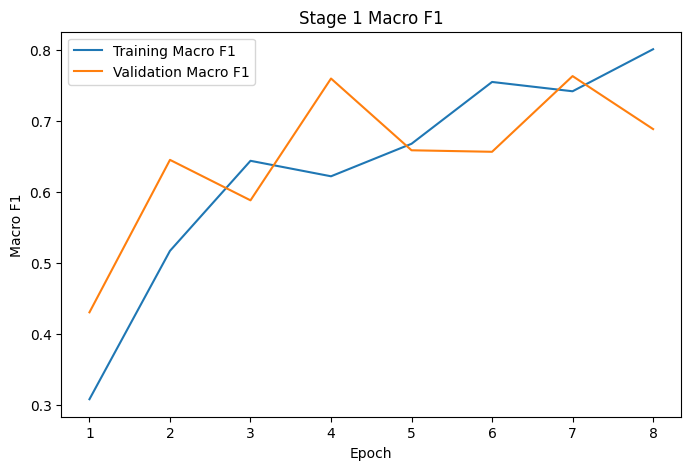

In [56]:
epochs_completed = torch.arange(1, 9, 1)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs_completed,
    stage1_history["train_f1"],
    label="Training Macro F1"
)

plt.plot(
    epochs_completed,
    stage1_history["val_f1"],
    label="Validation Macro F1"
)

plt.xlabel("Epoch")
plt.ylabel("Macro F1")
plt.title("Stage 1 Macro F1")
plt.legend()
plt.show()

In [62]:
# First freeze the entire network again.
for parameter in model.parameters():
    parameter.requires_grad = False


# Unfreeze only the final layer as it contains the highest level features
for parameter in model.layer4.parameters():
    parameter.requires_grad = True


# Our custom 6-class classifier must remain trainable.
for parameter in model.fc.parameters():
    parameter.requires_grad = True

In [63]:
trainable_parameter_count = 0
total_parameter_count = 0

for name, parameter in model.named_parameters():

    parameter_count = parameter.numel()

    total_parameter_count += parameter_count

    if parameter.requires_grad:
        trainable_parameter_count += parameter_count


print(
    "Total parameters:",
    f"{total_parameter_count:,}"
)

print(
    "Trainable parameters:",
    f"{trainable_parameter_count:,}"
)

print(
    "Frozen parameters:",
    f"{total_parameter_count - trainable_parameter_count:,}"
)

Total parameters: 31,303,203
Trainable parameters: 23,498,602
Frozen parameters: 7,804,601


In [64]:
# Stage 2 fine-tuning configuration

STAGE2_EPOCHS = 8

# Pretrained layers receive a much smaller learning rate because we only want to gently adapt them.
STAGE2_BACKBONE_LEARNING_RATE = 1e-5

# The custom classifier can change more aggressively.
STAGE2_CLASSIFIER_LEARNING_RATE = 1e-4

STAGE2_WEIGHT_DECAY = 1e-4

STAGE2_EARLY_STOPPING_PATIENCE = 3

P1_STAGE2_CHECKPOINT_PATH = os.path.join(
    CHECKPOINT_DIR,
    "p1_r2plus1d_stage2_best.pth"
)

print(
    "Backbone learning rate:",
    STAGE2_BACKBONE_LEARNING_RATE
)

print(
    "Classifier learning rate:",
    STAGE2_CLASSIFIER_LEARNING_RATE
)

Backbone learning rate: 1e-05
Classifier learning rate: 0.0001


In [65]:
# AdamW supports multiple parameter groups, allowing different parts of the model to use different learning rates.

stage2_optimizer = AdamW(
    [
        {
            "params": model.layer4.parameters(),
            "lr": STAGE2_BACKBONE_LEARNING_RATE
        },
        {
            "params": model.fc.parameters(),
            "lr": STAGE2_CLASSIFIER_LEARNING_RATE
        }
    ],
    weight_decay=STAGE2_WEIGHT_DECAY
)


# Create a fresh GradScaler for Stage 2.
stage2_scaler = torch.amp.GradScaler(
    "cuda",
    enabled=USE_AMP
)

In [66]:
def train_one_epoch_stage2(
    model,
    data_loader,
    criterion,
    optimizer,
    scaler,
    device
):

    # Keep the frozen backbone stable.
    model.eval()

    # Unfreeze only the layer4 and the classification layer
    model.layer4.train()
    model.fc.train()

    running_loss = 0.0
    correct_predictions = 0
    total_samples = 0

    all_predictions = []
    all_labels = []

    progress_bar = tqdm(
        data_loader,
        desc="Fine-tuning",
        leave=False
    )

    for videos, labels in progress_bar:

        videos = videos.to(
            device,
            non_blocking=True # Send the data to the GPU without forcing the CPU to wait until the transfer is fully finished.
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad(
            set_to_none=True #Slightly more memory efficient and faster
        )

        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=USE_AMP
        ):

            logits = model(videos)

            loss = criterion(
                logits,
                labels
            )


        scaler.scale(loss).backward()

        scaler.step(optimizer)

        scaler.update()


        predictions = torch.argmax(
            logits,
            dim=1
        )

        batch_size = labels.size(0)

        running_loss += (
            loss.item()
            * batch_size
        )

        correct_predictions += (
            predictions == labels
        ).sum().item()

        total_samples += batch_size

        all_predictions.extend(
            predictions.detach().cpu().tolist()
        )

        all_labels.extend(
            labels.detach().cpu().tolist()
        )

        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )


    average_loss = (
        running_loss
        / total_samples
    )

    accuracy = (
        correct_predictions
        / total_samples
    )

    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro"
    )


    return (
        average_loss,
        accuracy,
        macro_f1
    )

In [67]:
stage2_history = {
    "train_loss": [],
    "train_accuracy": [],
    "train_f1": [],
    "val_loss": [],
    "val_accuracy": [],
    "val_f1": []
}

In [68]:
best_stage2_val_f1 = -1.0
epochs_without_improvement = 0


for epoch in range(STAGE2_EPOCHS):

    print(
        f"\nStage 2 Epoch "
        f"{epoch + 1}/{STAGE2_EPOCHS}"
    )

    # Fine-tuning
    (
        train_loss,
        train_accuracy,
        train_f1
    ) = train_one_epoch_stage2(
        model=model,
        data_loader=train_loader,
        criterion=criterion,
        optimizer=stage2_optimizer,
        scaler=stage2_scaler,
        device=DEVICE
    )

    # Validation

    (
        val_loss,
        val_accuracy,
        val_f1
    ) = evaluate_model(
        model=model,
        data_loader=val_loader,
        criterion=criterion,
        device=DEVICE
    )


    # Store results.
    stage2_history["train_loss"].append(
        train_loss
    )

    stage2_history["train_accuracy"].append(
        train_accuracy
    )

    stage2_history["train_f1"].append(
        train_f1
    )

    stage2_history["val_loss"].append(
        val_loss
    )

    stage2_history["val_accuracy"].append(
        val_accuracy
    )

    stage2_history["val_f1"].append(
        val_f1
    )


    print(
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Train F1: {train_f1:.4f}"
    )

    print(
        f"Val Loss:   {val_loss:.4f} | "
        f"Val Acc:   {val_accuracy:.4f} | "
        f"Val F1:   {val_f1:.4f}"
    )

    if val_f1 > best_stage2_val_f1:

        best_stage2_val_f1 = val_f1

        epochs_without_improvement = 0

        stage2_checkpoint = {
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": stage2_optimizer.state_dict(),
            "scaler_state_dict": stage2_scaler.state_dict(),
            "val_f1": val_f1,
            "val_accuracy": val_accuracy,
            "class_to_index": CLASS_TO_INDEX,
            "num_frames": NUM_FRAMES,
            "frame_size": FRAME_SIZE
        }

        torch.save(
            stage2_checkpoint,
            P1_STAGE2_CHECKPOINT_PATH
        )

        print(
            "Best Stage 2 checkpoint saved "
            f"(Val F1 = {val_f1:.4f})"
        )


    else:

        epochs_without_improvement += 1

        print(
            "No validation improvement "
            f"for {epochs_without_improvement} epoch(s)."
        )


    # Early stopping
    if (
        epochs_without_improvement
        >= STAGE2_EARLY_STOPPING_PATIENCE
    ):

        print(
            "\nStage 2 early stopping triggered."
        )

        break


Stage 2 Epoch 1/8


Fine-tuning:   0%|          | 0/84 [00:00<?, ?it/s]

Validation:   0%|          | 0/21 [00:00<?, ?it/s]

Train Loss: 0.9578 | Train Acc: 0.6339 | Train F1: 0.6331
Val Loss:   0.7033 | Val Acc:   0.7857 | Val F1:   0.7874
Best Stage 2 checkpoint saved (Val F1 = 0.7874)

Stage 2 Epoch 2/8


Fine-tuning:   0%|          | 0/84 [00:00<?, ?it/s]

...

Validation:   0%|          | 0/21 [00:00<?, ?it/s]

Train Loss: 0.7530 | Train Acc: 0.7262 | Train F1: 0.7255
Val Loss:   0.5829 | Val Acc:   0.7857 | Val F1:   0.7868
No validation improvement for 2 epoch(s).

Stage 2 Epoch 6/8


Fine-tuning:   0%|          | 0/84 [00:00<?, ?it/s]

Validation:   0%|          | 0/21 [00:00<?, ?it/s]

Train Loss: 0.6517 | Train Acc: 0.7619 | Train F1: 0.7638
Val Loss:   0.5716 | Val Acc:   0.7738 | Val F1:   0.7746
No validation improvement for 3 epoch(s).

Stage 2 early stopping triggered.


In [69]:
stage2_checkpoint = torch.load(
    P1_STAGE2_CHECKPOINT_PATH,
    map_location=DEVICE
)

print(
    "Best Stage 2 epoch:",
    stage2_checkpoint["epoch"]
)

print(
    "Best Stage 2 validation F1:",
    f"{stage2_checkpoint['val_f1']:.4f}"
)

print(
    "Best Stage 2 validation accuracy:",
    f"{stage2_checkpoint['val_accuracy']:.4f}"
)

Best Stage 2 epoch: 3
Best Stage 2 validation F1: 0.7995
Best Stage 2 validation accuracy: 0.7976


In [70]:
stage1_val_f1 = (
    stage1_checkpoint["val_f1"]
)

stage2_val_f1 = (
    stage2_checkpoint["val_f1"]
)


print(
    "Stage 1 Validation F1:",
    f"{stage1_val_f1:.4f}"
)

print(
    "Stage 2 Validation F1:",
    f"{stage2_val_f1:.4f}"
)


if stage2_val_f1 > stage1_val_f1:

    print(
        "\nStage 2 performed better."
    )

    BEST_P1_CHECKPOINT_PATH = (
        P1_STAGE2_CHECKPOINT_PATH
    )

    BEST_P1_STAGE = "Stage 2"

else:

    print(
        "\nStage 1 performed better."
    )

    BEST_P1_CHECKPOINT_PATH = (
        P1_STAGE1_CHECKPOINT_PATH
    )

    BEST_P1_STAGE = "Stage 1"


print(
    "Selected final model:",
    BEST_P1_STAGE
)

Stage 1 Validation F1: 0.7631
Stage 2 Validation F1: 0.7995

Stage 2 performed better.
Selected final model: Stage 2


In [72]:
best_p1_checkpoint = torch.load(
    BEST_P1_CHECKPOINT_PATH,
    map_location=DEVICE
)

model.load_state_dict(
    best_p1_checkpoint["model_state_dict"]
)

model.eval()

print(
    "Final P1 model loaded:",
    BEST_P1_STAGE
)

print(
    "Validation F1:",
    f"{best_p1_checkpoint['val_f1']:.4f}"
)

Final P1 model loaded: Stage 2
Validation F1: 0.7995


In [73]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

def evaluate_test_set(
    model,
    data_loader,
    device
):

    # Evaluation mode disables training-specific behavior such as dropout.
    model.eval()

    all_labels = []
    all_predictions = []
    all_probabilities = []

    # inference_mode avoids storing gradients
    with torch.inference_mode():

        for videos, labels in tqdm(
            data_loader,
            desc="Testing"
        ):

            videos = videos.to(
                DEVICE,
                non_blocking=True
            )

            # Mixed precision during inference
            with torch.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=USE_AMP
            ):
                logits = model(videos)

            # Convert raw logits into class probabilities.
            probabilities = torch.softmax(
                logits,
                dim=1
            )

            # Class with the highest probability becomes the prediction.
            predictions = torch.argmax(
                probabilities,
                dim=1
            )

            all_labels.extend(
                labels.tolist()
            )

            all_predictions.extend(
                predictions.cpu().tolist()
            )

            all_probabilities.extend(
                probabilities.cpu().tolist()
            )

    return (
        all_labels,
        all_predictions,
        all_probabilities
    )

In [74]:
# Run inference on the untouched official test set.
(
    test_labels,
    test_predictions,
    test_probabilities
) = evaluate_test_set(
    model=model,
    data_loader=test_loader,
    device=DEVICE
)

print(
    "Test videos evaluated:",
    len(test_labels)
)

Testing:   0%|          | 0/45 [00:00<?, ?it/s]

Test videos evaluated: 180


In [76]:
# Overall percentage of correctly classified videos.
test_accuracy = accuracy_score(
    test_labels,
    test_predictions
)

# Macro metrics calculate the metric separately for every class and then average them equally.
# This prevents a class from dominating the result.
test_precision = precision_score(
    test_labels,
    test_predictions,
    average="macro",
    zero_division=0
)

test_recall = recall_score(
    test_labels,
    test_predictions,
    average="macro",
    zero_division=0
)

test_f1 = f1_score(
    test_labels,
    test_predictions,
    average="macro",
    zero_division=0
)


print(
    f"Test Accuracy:        {test_accuracy:.4f}"
)

print(
    f"Test Macro Precision: {test_precision:.4f}"
)

print(
    f"Test Macro Recall:    {test_recall:.4f}"
)

print(
    f"Test Macro F1:        {test_f1:.4f}"
)

Test Accuracy:        0.7222
Test Macro Precision: 0.7238
Test Macro Recall:    0.7222
Test Macro F1:        0.7184


In [80]:
print(
    classification_report(
        test_labels,
        test_predictions,
        target_names=SELECTED_CLASSES,
        digits=4,
        zero_division=0
    )
)

              precision    recall  f1-score   support

        clap     0.7083    0.5667    0.6296        30
        jump     0.8214    0.7667    0.7931        30
      pushup     0.9677    1.0000    0.9836        30
         run     0.7500    0.8000    0.7742        30
        walk     0.5750    0.7667    0.6571        30
        wave     0.5200    0.4333    0.4727        30

    accuracy                         0.7222       180
   macro avg     0.7238    0.7222    0.7184       180
weighted avg     0.7238    0.7222    0.7184       180



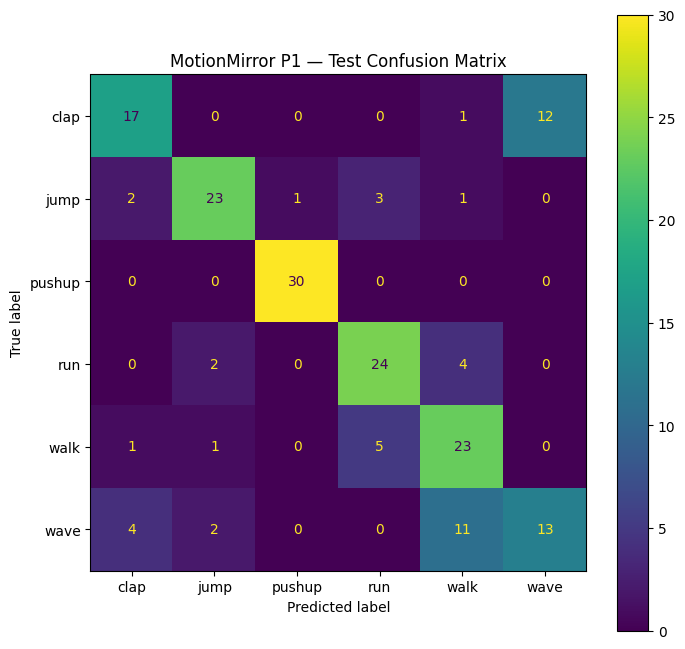

In [81]:
import matplotlib.pyplot as plt

from sklearn.metrics import ConfusionMatrixDisplay


# Create the confusion matrix.
test_confusion_matrix = confusion_matrix(
    test_labels,
    test_predictions
)


# Display it with readable class names.
display = ConfusionMatrixDisplay(
    confusion_matrix=test_confusion_matrix,
    display_labels=SELECTED_CLASSES
)

figure, axis = plt.subplots(
    figsize=(8, 8)
)

display.plot(
    ax=axis,
    values_format="d"
)

plt.title(
    "MotionMirror P1 — Test Confusion Matrix"
)

plt.show()

In [83]:
import json

OUTPUT_DIR = os.path.join(PROJECT_DIR, "output")

# Folder for Prototype 1 evaluation outputs.
P1_EVALUATION_DIR = os.path.join(
    OUTPUT_DIR,
    "prototype1",
    "evaluation"
)

os.makedirs(
    P1_EVALUATION_DIR,
    exist_ok=True
)


# Store the main metrics in a JSON file.
P1_METRICS_PATH = os.path.join(
    P1_EVALUATION_DIR,
    "test_metrics.json"
)

test_metrics = {
    "model_stage": BEST_P1_STAGE,
    "accuracy": float(test_accuracy),
    "macro_precision": float(test_precision),
    "macro_recall": float(test_recall),
    "macro_f1": float(test_f1),
    "number_of_test_videos": len(test_labels),
    "classes": SELECTED_CLASSES
}

with open(
    P1_METRICS_PATH,
    "w"
) as file:

    json.dump(
        test_metrics,
        file,
        indent=4
    )


print(
    "Test metrics saved to:",
    P1_METRICS_PATH
)

Test metrics saved to: /content/drive/MyDrive/MotionMirror/output/prototype1/evaluation/test_metrics.json


In [84]:
# Create a table containing the result for every test video.

test_results_df = test_df[
    [
        "video_path",
        "video_name",
        "action",
        "label"
    ]
].copy()


test_results_df["predicted_label"] = (
    test_predictions
)

test_results_df["predicted_action"] = [
    INDEX_TO_CLASS[label]
    for label in test_predictions
]


# Confidence = probability assigned to the predicted class.
test_results_df["confidence"] = [
    probabilities[prediction]
    for probabilities, prediction in zip(
        test_probabilities,
        test_predictions
    )
]


test_results_df["correct"] = (
    test_results_df["label"]
    ==
    test_results_df["predicted_label"]
)


P1_TEST_RESULTS_PATH = os.path.join(
    P1_EVALUATION_DIR,
    "test_predictions.csv"
)

test_results_df.to_csv(
    P1_TEST_RESULTS_PATH,
    index=False
)


print(
    "Predictions saved to:",
    P1_TEST_RESULTS_PATH
)

test_results_df.head()

Predictions saved to: /content/drive/MyDrive/MotionMirror/output/prototype1/evaluation/test_predictions.csv


,video_path,video_name,action,label,predicted_label,predicted_action,confidence,correct
0,/content/HMDB51_P1/videos/clap/clap/103_years_...,103_years_old_japanese_woman__Nao_is_clapping_...,clap,0,0,clap,0.603027,True
1,/content/HMDB51_P1/videos/clap/clap/103_years_...,103_years_old_japanese_woman__Nao_is_clapping_...,clap,0,0,clap,0.587891,True
2,/content/HMDB51_P1/videos/clap/clap/Aishwarya_...,Aishwarya_Rai_Burns_David_Letterman_in_his_own...,clap,0,0,clap,0.841309,True
3,/content/HMDB51_P1/videos/clap/clap/Alex_appla...,Alex_applauding_himself_clap_u_cm_np1_fr_med_1...,clap,0,0,clap,0.742188,True
4,/content/HMDB51_P1/videos/clap/clap/Alex_appla...,Alex_applauding_himself_clap_u_nm_np1_fr_med_0...,clap,0,0,clap,0.797852,True


In [87]:
# Copy whichever checkpoint performed best during model development
# into one fixed filename that the inference notebook can always use.

FINAL_P1_CHECKPOINT_PATH = os.path.join(
    CHECKPOINT_DIR,
    "p1_r2plus1d_final.pth"
)

shutil.copy2(
    BEST_P1_CHECKPOINT_PATH,
    FINAL_P1_CHECKPOINT_PATH
)

print("Final P1 checkpoint saved to:")
print(FINAL_P1_CHECKPOINT_PATH)

print("Selected model stage:")
print(BEST_P1_STAGE)

Final P1 checkpoint saved to:
/content/drive/MyDrive/MotionMirror/checkpoints/p1_r2plus1d_final.pth
Selected model stage:
Stage 2
